# 1. Título
## Fiscalização Ambiental e Autos de Infração do IBAMA em 2026 (Janeiro a Outubro)
**DCC011: Introdução a Banco de Dados — 2026/2**

# 2. Membros (nome e número de matrícula)
* **Evandro Araújo Furlaneto Delgado** — Matrícula: 2025018830
* **Letícia Schmidt Tolentino Santos** — Matrícula: 2025014168
* **Victor Daniel Barbosa Thomé** — Matrícula: 2026303953
* **Vitória Medeiros Carrera de Oliveira** — Matrícula: 2019027245
* **Yuri Florentino Kosfeld** — Matrícula: 2022038503

# 3. Descrição dos dados (qual a URL? qual o domínio? como os dados foram processados?)

### 3.1 Identificação e Domínio dos Dados
* **Tema:** Fiscalização Ambiental Federal e Autos de Infração do IBAMA em 2026.
* **Conjunto de Dados:** *Fiscalização – Auto de Infração* (Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis – IBAMA).
* **Fonte / URL:** [dados.gov.br/dados/conjuntos-dados/fiscalizacao-auto-de-infracao](https://dados.gov.br/dados/conjuntos-dados/fiscalizacao-auto-de-infracao).
* **Arquivo Base:** `auto_infracao_2026.csv`, atualizado em 27/10/2026, com 13.648 linhas e 84 colunas sobre autos lavrados de janeiro a outubro de 2026 em todas as 27 UFs.
* **Domínio:** Registros de infrações e sanções administrativas ambientais aplicadas pelo órgão federal sobre desmatamento ilegal, comércio de fauna silvestre, pesca predatória, poluição industrial e descumprimento de embargos.

---

### 3.2 Dicionário dos Principais Atributos Originais
* `SEQ_AUTO_INFRACAO`: Identificador sequencial do auto no sistema legador.
* `DES_STATUS_FORMULARIO`: Situação do auto (Lavrado, Cancelado, Danificado, etc.).
* `NUM_AUTO_INFRACAO`: Código alfanumérico identificador único do Auto de Infração (emitido pelo sistema eletrônico AIe).
* `TIPO_AUTO`: Sanção proposta (Multa simples, Multa diária, Advertência).
* `VAL_AUTO_INFRACAO`: Valor pecuniário da multa indicada pelo agente fiscal (em Reais).
* `GRAVIDADE_INFRACAO`: Gravidade da infração constatada (Baixa, Média, Grave).
* `DES_AUTO_INFRACAO`: Descrição circunstanciada do fato infracional.
* `FORMA_ENTREGA`: Meio empregado para dar ciência da autuação (Pessoalmente, Notificação, Edital, etc.).
* `DES_LOCAL_INFRACAO`: Descrição textual do local físico da ocorrência.
* `DS_BIOMAS_ATINGIDOS`: Bioma ou biomas afetados pela conduta infracional.
* `UNID_CONTROLE`: Unidade administrativa de fiscalização responsável pelo auto.
* `DAT_HORA_AUTO_INFRACAO`: Data e horário da lavratura do formulário de autuação.
* `COD_MUNICIPIO`: Código IBGE do município da infração.
* `MUNICIPIO`: Nome do município da infração.
* `UF`: Sigla da Unidade Federativa.
* `COD_INFRACAO`: Código tipificador legal da infração.
* `DES_INFRACAO`: Descrição jurídica da conduta tipificada.
* `TIPO_INFRACAO`: Classificação macro da conduta (Flora, Fauna, Pesca, Controle Ambiental, etc.).
* `NOME_INFRATOR`: Nome ou razão social da pessoa autuada.
* `CPF_CNPJ_INFRATOR`: Documento CPF ou CNPJ do infrator autuado.
* `TP_PESSOA_INFRATOR`: Tipo de personalidade jurídica (PF - Pessoa Física, PJ - Pessoa Jurídica).
* `NUM_LATITUDE_AUTO` / `NUM_LONGITUDE_AUTO`: Coordenadas geográficas decimais.
* `ORDEM_FISCALIZACAO`: Código alfanumérico da ordem de fiscalização institucional de campo.
* `UNID_ORDENADORA`: Unidade administrativa expedidora da ordem fiscal.
* `OPERACAO_SOL_RECURSO`: Nome da operação especial de fiscalização planejada em campo.

---

### 3.3 Modelo Relacional Normalizado Proposto
Em total alinhamento com a proposta oficial submetida (`TP2_IBD_PROPOSTA.md`), a base desnormalizada de 84 atributos foi decomposta em **5 tipos de entidade** e **1 relação associativa muitos-para-muitos (M:N)**:

1. **`INFRATOR` (9.858 instâncias):**
   * PK: `id_infrator` (chave substituta inteira). Cada infrator corresponde a um CPF/CNPJ distinto (normalizado só com dígitos); quando o documento não foi informado, à combinação nome + tipo de pessoa.
   * Atributos: `nome_infrator`, `tipo_pessoa`, `cpf_cnpj`.
2. **`MUNICIPIO` (1.674 instâncias):**
   * PK: `cod_municipio` (código oficial IBGE).
   * Atributos: `nome_municipio`, `uf`.
3. **`ORDEM_FISCALIZACAO` (872 instâncias):**
   * PK: `codigo_ordem` (da coluna `ORDEM_FISCALIZACAO`).
   * Atributos: `unidade_ordenadora`, `nome_operacao` (da coluna `OPERACAO_SOL_RECURSO`).
4. **`TIPO_INFRACAO` (23 instâncias):**
   * PK: `id_tipo` (chave substituta inteira identificando cada enquadramento).
   * Atributos: `cod_infracao`, `descricao_infracao`, `tipo_infracao`.
5. **`AUTO_INFRACAO` (13.619 instâncias):**
   * PK: `num_auto_infracao` (código alfanumérico do auto).
   * Atributos: `data_hora`, `valor_multa`, `tipo_auto`, `descricao_fato`, `forma_entrega`, `local`, `bioma`, `unidade_controle`, `latitude`, `longitude`.
   * Chaves Estrangeiras: `id_infrator` (FK $\rightarrow$ Infrator), `cod_municipio` (FK $\rightarrow$ Municipio), `id_tipo` (FK $\rightarrow$ Tipo_Infracao), `codigo_ordem` (FK $\rightarrow$ Ordem_Fiscalizacao).
6. **`AUTUADO_EM` (10.172 instâncias - Relacionamento M:N):**
   * Chave Composta: (`id_infrator`, `codigo_ordem`).
   * Modela em quais ordens e missões de fiscalização cada infrator foi autuado, capturando casos em que uma ordem autua múltiplos agentes e agentes são alvos de múltiplas ordens ao longo do ano.

---

### 3.4 Pré-processamento e Carga dos Dados no SQLite
O script a seguir implementa a ingestão autônoma:
* Verifica a presença de `auto_infracao_csv/auto_infracao_2026.csv` ou descompacta `auto_infracao_2026.csv` a partir do zip `auto_infracao_csv.zip`.
* Remove as linhas repetidas de um mesmo auto (29 linhas): o arquivo traz alguns autos em mais de uma versão (ex.: Lavrado e Cancelado). Mantém-se uma linha por `NUM_AUTO_INFRACAO`, priorizando a versão com status *Lavrado*, e todas as tabelas são povoadas a partir dessa base deduplicada.
* Padroniza o `CPF_CNPJ_INFRATOR` mantendo apenas os dígitos, pois o mesmo documento aparecia com e sem pontuação (ex.: `00.058.722/0001-05` e `00058722000105`), o que duplicava infratores.
* Converte números no formato brasileiro com vírgula para `REAL`.
* Executa o DDL e povoa as tabelas normalizadas em SQLite (`auto_infracao.db`).
* Povoa `Autuado_Em` por último, a partir dos autos já carregados (`SELECT DISTINCT id_infrator, codigo_ordem FROM Auto_Infracao`), garantindo que todo par infrator–ordem corresponda a pelo menos um auto.

In [1]:
import os
import zipfile
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Funções utilitárias de acesso ao SQLite
def fetch(query, conn, formatted=True):
    cur = conn.cursor()
    cur.execute(query)
    rs = cur.fetchall()
    columns = [desc[0] for desc in cur.description]
    cur.close()
    return pd.DataFrame(rs, columns=columns) if formatted else rs

def show_tables(conn):
    return [x[0] for x in fetch('SELECT tbl_name FROM sqlite_master WHERE type="table"', conn, False)]

def shape(table, conn):
    nrows = fetch(f'SELECT COUNT(*) FROM {table}', conn, False)[0][0]
    ncols = fetch(f'SELECT COUNT(*) FROM pragma_table_info("{table}")', conn, False)[0][0]
    return (nrows, ncols)

print("Bibliotecas e funções auxiliares carregadas com sucesso.")

/home/ykosfeld/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-7_u_ywic because there was an issue with the default path ({configdir}); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Bibliotecas e funções auxiliares carregadas com sucesso.


In [2]:
# 1. Localização e Descompactação dos Dados
csv_candidates = [
    os.path.join('auto_infracao_csv', 'auto_infracao_2026.csv'),
    'auto_infracao_2026.csv'
]

csv_file = None
for path in csv_candidates:
    if os.path.exists(path):
        csv_file = path
        break

if not csv_file:
    zip_path = 'auto_infracao_csv.zip'
    if os.path.exists(zip_path):
        print(f"Descompactando auto_infracao_2026.csv a partir de {zip_path}...")
        extract_dir = 'auto_infracao_csv'
        os.makedirs(extract_dir, exist_ok=True)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            target_file = None
            for member in zip_ref.namelist():
                if member.endswith('auto_infracao_2026.csv'):
                    target_file = member
                    break
            if target_file:
                zip_ref.extract(target_file, extract_dir)
                csv_file = os.path.join(extract_dir, os.path.basename(target_file))
            else:
                raise FileNotFoundError("auto_infracao_2026.csv não encontrado no arquivo zip.")
    else:
        raise FileNotFoundError("Base de dados não encontrada (verifique auto_infracao_csv/ ou auto_infracao_csv.zip).")

print(f"Carregando dados a partir de: {csv_file}")
# CPF/CNPJ lido como texto para não perder zeros à esquerda
df_raw = pd.read_csv(csv_file, sep=';', encoding='utf-8', low_memory=False,
                     dtype={'CPF_CNPJ_INFRATOR': str})
print(f"Registros brutos lidos: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")

# 2. Limpeza prévia

# Correção 2 - Autos repetidos: o mesmo NUM_AUTO_INFRACAO aparece em mais de uma linha,
# às vezes com uma versão Cancelada/Excluída. Mantemos uma linha por auto, priorizando
# a versão 'Lavrado'. Todas as tabelas são povoadas a partir desta base deduplicada,
# para que nenhuma entidade guarde dados vindos de versões descartadas.
prioridade_status = df_raw['DES_STATUS_FORMULARIO'].map({'Lavrado': 0}).fillna(1)
df_base = (df_raw.assign(_prioridade=prioridade_status)
                 .sort_values(['NUM_AUTO_INFRACAO', '_prioridade'], kind='stable')
                 .drop_duplicates(subset=['NUM_AUTO_INFRACAO'], keep='first')
                 .drop(columns='_prioridade')
                 .reset_index(drop=True))
print(f"Linhas repetidas de autos removidas: {len(df_raw) - len(df_base)} "
      f"({len(df_base)} autos únicos).")

# Correção 1 - CPF/CNPJ com e sem pontuação: o mesmo documento aparecia como
# '00.058.722/0001-05' e '00058722000105', gerando dois infratores. Mantemos só os dígitos.
df_base['CPF_CNPJ_INFRATOR'] = df_base['CPF_CNPJ_INFRATOR'].str.replace(r'\D', '', regex=True)
df_base.loc[df_base['CPF_CNPJ_INFRATOR'] == '', 'CPF_CNPJ_INFRATOR'] = None

# 3. Conexão e Criação do Banco SQLite
db_name = 'auto_infracao.db'
if os.path.exists(db_name):
    os.remove(db_name)

conn = sqlite3.connect(db_name)
cur = conn.cursor()

# Otimizações de ingestão
cur.execute('PRAGMA foreign_keys = 0;')
cur.execute('PRAGMA synchronous = OFF;')
cur.execute('PRAGMA journal_mode = MEMORY;')

# DDL das 5 Tabelas e 1 Tabela Associativa M:N (TP2_IBD_PROPOSTA.md)
cur.executescript('''
CREATE TABLE Municipio (
    cod_municipio INTEGER PRIMARY KEY,
    nome_municipio TEXT NOT NULL,
    uf TEXT NOT NULL
);

CREATE TABLE Infrator (
    id_infrator INTEGER PRIMARY KEY AUTOINCREMENT,
    nome_infrator TEXT NOT NULL,
    tipo_pessoa TEXT,
    cpf_cnpj TEXT
);

CREATE TABLE Ordem_Fiscalizacao (
    codigo_ordem TEXT PRIMARY KEY,
    unidade_ordenadora TEXT NOT NULL,
    nome_operacao TEXT
);

CREATE TABLE Tipo_Infracao (
    id_tipo INTEGER PRIMARY KEY AUTOINCREMENT,
    cod_infracao INTEGER NOT NULL,
    descricao_infracao TEXT NOT NULL,
    tipo_infracao TEXT NOT NULL
);

CREATE TABLE Autuado_Em (
    id_infrator INTEGER NOT NULL,
    codigo_ordem TEXT NOT NULL,
    PRIMARY KEY (id_infrator, codigo_ordem),
    FOREIGN KEY (id_infrator) REFERENCES Infrator(id_infrator),
    FOREIGN KEY (codigo_ordem) REFERENCES Ordem_Fiscalizacao(codigo_ordem)
);

CREATE TABLE Auto_Infracao (
    num_auto_infracao TEXT PRIMARY KEY,
    data_hora TEXT NOT NULL,
    valor_multa REAL,
    tipo_auto TEXT,
    descricao_fato TEXT,
    forma_entrega TEXT,
    local TEXT,
    bioma TEXT,
    unidade_controle TEXT,
    latitude REAL,
    longitude REAL,
    id_infrator INTEGER NOT NULL,
    cod_municipio INTEGER NOT NULL,
    id_tipo INTEGER NOT NULL,
    codigo_ordem TEXT,
    FOREIGN KEY (id_infrator) REFERENCES Infrator(id_infrator),
    FOREIGN KEY (cod_municipio) REFERENCES Municipio(cod_municipio),
    FOREIGN KEY (id_tipo) REFERENCES Tipo_Infracao(id_tipo),
    FOREIGN KEY (codigo_ordem) REFERENCES Ordem_Fiscalizacao(codigo_ordem)
);
''')
cur.close()
conn.commit()

# 4. Povoamento das Entidades Normalizadas

# A. Municipio
mun = df_base[['COD_MUNICIPIO', 'MUNICIPIO', 'UF']].dropna(subset=['COD_MUNICIPIO']).drop_duplicates(subset=['COD_MUNICIPIO']).copy()
mun.columns = ['cod_municipio', 'nome_municipio', 'uf']
mun['cod_municipio'] = mun['cod_municipio'].astype(int)
mun.to_sql('Municipio', conn, if_exists='append', index=False)

# B. Infrator - identificado pelo CPF/CNPJ (só dígitos). Quando o documento está vazio,
# o infrator é identificado pela combinação nome + tipo de pessoa.
df_base['chave_infrator'] = df_base['CPF_CNPJ_INFRATOR'].where(
    df_base['CPF_CNPJ_INFRATOR'].notna(),
    'SEM_DOC|' + df_base['NOME_INFRATOR'].astype(str) + '|' + df_base['TP_PESSOA_INFRATOR'].fillna('').astype(str)
)
# Para documentos registrados com nomes diferentes, fica o nome mais frequente
inf = (df_base.groupby('chave_infrator', sort=False)
              .agg(nome_infrator=('NOME_INFRATOR', lambda s: s.mode().iloc[0]),
                   tipo_pessoa=('TP_PESSOA_INFRATOR', 'first'),
                   cpf_cnpj=('CPF_CNPJ_INFRATOR', 'first'))
              .reset_index())
inf['id_infrator'] = inf.index + 1
inf[['id_infrator', 'nome_infrator', 'tipo_pessoa', 'cpf_cnpj']].to_sql('Infrator', conn, if_exists='append', index=False)

# C. Ordem_Fiscalizacao
ordem = df_base[['ORDEM_FISCALIZACAO', 'UNID_ORDENADORA', 'OPERACAO_SOL_RECURSO']].dropna(subset=['ORDEM_FISCALIZACAO']).drop_duplicates(subset=['ORDEM_FISCALIZACAO']).copy()
ordem.columns = ['codigo_ordem', 'unidade_ordenadora', 'nome_operacao']
ordem.to_sql('Ordem_Fiscalizacao', conn, if_exists='append', index=False)

# D. Tipo_Infracao
tipo = df_base[['COD_INFRACAO', 'DES_INFRACAO', 'TIPO_INFRACAO']].drop_duplicates().copy().reset_index(drop=True)
tipo['id_tipo'] = tipo.index + 1
tipo.columns = ['cod_infracao', 'descricao_infracao', 'tipo_infracao', 'id_tipo']
tipo['cod_infracao'] = tipo['cod_infracao'].astype(int)
tipo[['id_tipo', 'cod_infracao', 'descricao_infracao', 'tipo_infracao']].to_sql('Tipo_Infracao', conn, if_exists='append', index=False)

# E. Auto_Infracao (uma linha por auto, já deduplicada na etapa 2)
df_auto = (df_base.merge(inf[['chave_infrator', 'id_infrator']], on='chave_infrator', how='left')
                  .merge(tipo, left_on=['COD_INFRACAO', 'DES_INFRACAO', 'TIPO_INFRACAO'],
                         right_on=['cod_infracao', 'descricao_infracao', 'tipo_infracao'], how='left'))

def clean_float(val):
    if pd.isna(val):
        return None
    val_str = str(val).replace('.', '').replace(',', '.')
    try:
        return float(val_str)
    except:
        return None

df_auto['valor_multa'] = df_auto['VAL_AUTO_INFRACAO'].apply(clean_float)
df_auto['latitude'] = df_auto['NUM_LATITUDE_AUTO'].apply(clean_float)
df_auto['longitude'] = df_auto['NUM_LONGITUDE_AUTO'].apply(clean_float)

auto = df_auto[['NUM_AUTO_INFRACAO', 'DAT_HORA_AUTO_INFRACAO', 'valor_multa', 'TIPO_AUTO', 'DES_AUTO_INFRACAO', 'FORMA_ENTREGA', 'DES_LOCAL_INFRACAO', 'DS_BIOMAS_ATINGIDOS', 'UNID_CONTROLE', 'latitude', 'longitude', 'id_infrator', 'COD_MUNICIPIO', 'id_tipo', 'ORDEM_FISCALIZACAO']].copy()
auto.columns = ['num_auto_infracao', 'data_hora', 'valor_multa', 'tipo_auto', 'descricao_fato', 'forma_entrega', 'local', 'bioma', 'unidade_controle', 'latitude', 'longitude', 'id_infrator', 'cod_municipio', 'id_tipo', 'codigo_ordem']
auto['cod_municipio'] = auto['cod_municipio'].astype(int)
auto.to_sql('Auto_Infracao', conn, if_exists='append', index=False)

# F. Autuado_Em (Relação M:N)
# Correção 3 - montada a partir dos autos já carregados, para que todo par
# infrator-ordem corresponda a pelo menos um auto existente.
cur = conn.cursor()
cur.execute('''
INSERT INTO Autuado_Em (id_infrator, codigo_ordem)
SELECT DISTINCT id_infrator, codigo_ordem
FROM Auto_Infracao
WHERE codigo_ordem IS NOT NULL;
''')
conn.commit()

# Reativação de garantias de integridade
cur.execute('PRAGMA foreign_keys = 1;')
cur.execute('PRAGMA synchronous = FULL;')
cur.execute('PRAGMA journal_mode = DELETE;')
cur.close()
print("Banco de dados 'auto_infracao.db' criado e populado conforme TP2_IBD_PROPOSTA.md!")

Carregando dados a partir de: auto_infracao_csv/auto_infracao_2026.csv


Registros brutos lidos: 13648 linhas e 84 colunas.
Linhas repetidas de autos removidas: 29 (13619 autos únicos).


Banco de dados 'auto_infracao.db' criado e populado conforme TP2_IBD_PROPOSTA.md!


In [3]:
# Resumo das instâncias populadas em conformidade com TP2_IBD_PROPOSTA.md
tables = ['Infrator', 'Municipio', 'Ordem_Fiscalizacao', 'Tipo_Infracao', 'Autuado_Em', 'Auto_Infracao']
summary = []
for t in tables:
    nrows, ncols = shape(t, conn)
    summary.append({'Tabela': t, 'Colunas': ncols, 'Instâncias (Tuplas)': nrows})

df_summary = pd.DataFrame(summary)
print("=== RESUMO DO BANCO DE DADOS NORMALIZADO ===")
print(df_summary.to_string(index=False))
print(f"\nTotal Geral de Instâncias no Modelo: {df_summary['Instâncias (Tuplas)'].sum():,}")

=== RESUMO DO BANCO DE DADOS NORMALIZADO ===
            Tabela  Colunas  Instâncias (Tuplas)
          Infrator        4                 9858
         Municipio        3                 1674
Ordem_Fiscalizacao        3                  872
     Tipo_Infracao        4                   23
        Autuado_Em        2                10172
     Auto_Infracao       15                13619

Total Geral de Instâncias no Modelo: 36,218


# 4. Diagrama ER

Abaixo é apresentado o Diagrama Entidade-Relacionamento (ER) Conceitual projetado para a fiscalização ambiental do IBAMA em 2026, em estrita conformidade com a proposta aprovada ([TP2_IBD_PROPOSTA.md](TP2_IBD_PROPOSTA.md)):

### Componentes do Modelo Conceitual:
* **Entidades:**
  * **INFRATOR:** Pessoa física ou jurídica penalizada (`id_infrator` [PK], `nome_infrator`, `tipo_pessoa`, `cpf_cnpj`).
  * **MUNICIPIO:** Localidade geográfica (`cod_municipio` [PK], `nome_municipio`, `uf`).
  * **ORDEM_FISCALIZACAO:** Missão/ação fiscal de campo (`codigo_ordem` [PK], `unidade_ordenadora`, `nome_operacao`).
  * **TIPO_INFRACAO:** Enquadramento jurídico da conduta (`id_tipo` [PK], `cod_infracao`, `descricao_infracao`, `tipo_infracao`).
  * **AUTO_INFRACAO:** Documento/ato fiscalizatório (`num_auto_infracao` [PK], `data_hora`, `valor_multa`, `tipo_auto`, `descricao_fato`, `forma_entrega`, `local`, `bioma`, `unidade_controle`, `latitude`, `longitude`).

* **Relacionamentos e Cardinalidades:**
  * **`RECEBE` (INFRATOR, AUTO_INFRACAO):** 1:N (ou M:N conceitual com 13.619 instâncias). Cada auto referencia o agente autuado e um infrator pode receber múltiplos autos.
  * **`OCORRE_EM` (MUNICIPIO, AUTO_INFRACAO):** 1:N (13.619 instâncias). Um município sedia múltiplos autos; cada auto ocorre em uma localidade.
  * **`ENQUADRA` (TIPO_INFRACAO, AUTO_INFRACAO):** 1:N (13.619 instâncias). Cada auto é enquadrado em uma tipificação legal.
  * **`DECORRE_DE` (ORDEM_FISCALIZACAO, AUTO_INFRACAO):** 1:N (13.466 instâncias). Autos originados a partir de ordens fiscalizatórias planejadas.
  * **`AUTUADO_EM` (INFRATOR, ORDEM_FISCALIZACAO):** **M:N (10.172 instâncias)**. Relacionamento muitos-para-muitos legítimo entre infratores e ordens de fiscalização de campo (uma missão autua dezenas de infratores, e agentes reincidentes são alvos de múltiplas ordens ao longo do ano).

```
+--------------------+        AUTUADO_EM (M:N)        +----------------------+
|      INFRATOR      | <============================> |  ORDEM_FISCALIZACAO  |
+--------------------+                                +----------------------+
         | (1)                                                   | (1)
       RECEBE                                                DECORRE_DE
         | (N)                                                   | (N)
   +----------------------------------------------------------------------+
   |                             AUTO_INFRACAO                            |
   +----------------------------------------------------------------------+
         | (N)                                                   | (N)
     OCORRE_EM                                                ENQUADRA
         | (1)                                                   | (1)
+--------------------+                                +----------------------+
|     MUNICIPIO      |                                |    TIPO_INFRACAO     |
+--------------------+                                +----------------------+
```

![Diagrama ER Conceitual](graficos/diagrama_er.png)

# 5. Diagrama relacional

Abaixo é apresentado o Esquema Lógico Relacional Normalizado resultante do mapeamento do modelo ER em Terceira Forma Normal (3FN):

* **`Municipio`** (**`cod_municipio`**, `nome_municipio`, `uf`)
  * Chave Primária: `cod_municipio` (Código oficial IBGE).
---
* **`Infrator`** (**`id_infrator`**, `nome_infrator`, `tipo_pessoa`, `cpf_cnpj`)
  * Chave Primária: `id_infrator` (Chave surrogate inteira).
---
* **`Ordem_Fiscalizacao`** (**`codigo_ordem`**, `unidade_ordenadora`, `nome_operacao`)
  * Chave Primária: `codigo_ordem` (Identificador alfanumérico da ordem).
---
* **`Tipo_Infracao`** (**`id_tipo`**, `cod_infracao`, `descricao_infracao`, `tipo_infracao`)
  * Chave Primária: `id_tipo`.
---
* **`Autuado_Em`** (**`_id_infrator_`**, **`_codigo_ordem_`**)
  * Chave Primária Composta: (`id_infrator`, `codigo_ordem`).
  * Chave Estrangeira: `id_infrator` referencia `Infrator(id_infrator)`.
  * Chave Estrangeira: `codigo_ordem` referencia `Ordem_Fiscalizacao(codigo_ordem)`.
---
* **`Auto_Infracao`** (**`num_auto_infracao`**, `data_hora`, `valor_multa`, `tipo_auto`, `descricao_fato`, `forma_entrega`, `local`, `bioma`, `unidade_controle`, `latitude`, `longitude`, `_id_infrator_`, `_cod_municipio_`, `_id_tipo_`, `_codigo_ordem_`)
  * Chave Primária: `num_auto_infracao`.
  * Chave Estrangeira: `id_infrator` referencia `Infrator(id_infrator)`.
  * Chave Estrangeira: `cod_municipio` referencia `Municipio(cod_municipio)`.
  * Chave Estrangeira: `id_tipo` referencia `Tipo_Infracao(id_tipo)`.
  * Chave Estrangeira: `codigo_ordem` referencia `Ordem_Fiscalizacao(codigo_ordem)`.
---
Todas as restrições de domínio, unicidade e integridade referencial estão formalmente implementadas no SGBD SQLite.

# 6. Consultas

## 6.1 Duas consultas envolvendo seleção e projeção

### 6.1.1 Consulta 1
**Descrição:** Identificar as autuações graves que receberam sanção da modalidade "Multa simples" com valor igual ou superior a `R$ 1.000.000,00` aplicadas em 2026, projetando o número do auto, data/hora, valor da penalidade, tipo do auto e o bioma atingido, ordenadas de forma decrescente pelo valor (Investigação: Distribuição dos valores e concentração acima de `R$ 1M`).

In [4]:
query1 = """
SELECT num_auto_infracao, data_hora, valor_multa, tipo_auto, bioma
FROM Auto_Infracao
WHERE valor_multa >= 1000000 AND tipo_auto = 'Multa simples'
ORDER BY valor_multa DESC
LIMIT 10;
"""

fetch(query1, conn)

,num_auto_infracao,data_hora,valor_multa,tipo_auto,bioma
0,CHPIEBY0,2026-10-16 12:20:21,50000000.0,Multa simples,Amazonia
1,FVNEIYIX,2026-06-16 15:42:01,50000000.0,Multa simples,Amazonia
2,Q8VFCM4C,2026-08-26 13:49:43,50000000.0,Multa simples,Pantanal
3,T17JFB25,2026-10-27 15:28:01,50000000.0,Multa simples,Costeiro e Marinho
4,TEPY3KCP,2026-08-21 21:45:58,50000000.0,Multa simples,Pantanal
5,20APLWL5,2026-06-17 16:31:06,45110000.0,Multa simples,Amazonia
6,ZKX7HI3G,2026-05-18 15:01:00,44174400.0,Multa simples,Amazonia
7,98V6QE5G,2026-09-03 18:11:09,35055000.0,Multa simples,Amazonia
8,F0UXVWJ1,2026-04-14 12:27:20,35055000.0,Multa simples,Amazonia
9,W3N3MOKV,2026-03-24 12:29:16,34801100.0,Multa simples,Amazonia


### 6.1.2 Consulta 2
**Descrição:** Listar os infratores cadastrados como Pessoa Jurídica (PJ) que possuem número de CNPJ registrado, projetando o identificador do infrator, razão social e número fiscal de inscrição, ordenados alfabeticamente (Investigação: Perfil dos infratores PJ autuados).

In [5]:
query2 = """
SELECT id_infrator, nome_infrator, cpf_cnpj, tipo_pessoa
FROM Infrator
WHERE tipo_pessoa = 'PJ' AND cpf_cnpj IS NOT NULL
ORDER BY nome_infrator ASC
LIMIT 10;
"""

fetch(query2, conn)

,id_infrator,nome_infrator,cpf_cnpj,tipo_pessoa
0,4031,CASA DA MADEIRA LTDA,10418988000167,PJ
1,5798,POLE COFFEE EXPORTACAO E IMPORTACAO LTDA,07953619000160,PJ
2,8053,137 PESCADOS LTDA,61215914000164,PJ
3,393,2A COMERCIO DE GAS E BEBIDAS LTDA,15611034000190,PJ
4,1729,32850515 MARIANA AYALA RIBEIRO,32850515000177,PJ
5,2196,3E COMERCIAL LTDA,52584160000129,PJ
6,8019,3J AGRO E PARTICIPACÕES ESPECIAIS LTDA,35216667000453,PJ
7,248,3JS COMERCIO DE MADEIRAS EIRELI ME,42785991000105,PJ
8,6736,3M PARTICIPAÇÕES LTDA,00436476000170,PJ
9,4604,3N TRANSPORTES LTDA,22304126000192,PJ


## 6.2 Três consultas envolvendo junção de duas relações

### 6.2.1 Consulta 3
**Descrição:** Junção entre `Auto_Infracao` e `Infrator` para identificar quais agentes (pessoas físicas ou jurídicas) receberam as maiores multas individuais lavradas em 2026, projetando número do auto, nome do infrator, tipo de pessoa, valor da multa, data e bioma afetado (Investigação: Maiores infratores do país).

In [6]:
query3 = """
SELECT a.num_auto_infracao, i.nome_infrator, i.tipo_pessoa, a.valor_multa, a.data_hora, a.bioma
FROM Auto_Infracao a
JOIN Infrator i ON a.id_infrator = i.id_infrator
WHERE a.valor_multa IS NOT NULL
ORDER BY a.valor_multa DESC
LIMIT 10;
"""

fetch(query3, conn)

,num_auto_infracao,nome_infrator,tipo_pessoa,valor_multa,data_hora,bioma
0,CHPIEBY0,JARI CELULOSE PAPEL E EMBALAGENS SA,PJ,50000000.0,2026-10-16 12:20:21,Amazonia
1,FVNEIYIX,METALMIG MINERAÇÃO INDÚSTRIA E COMÉRCIO LTDA,PJ,50000000.0,2026-06-16 15:42:01,Amazonia
2,Q8VFCM4C,PLÍNIO JUNQUEIRA JÚNIOR,PF,50000000.0,2026-08-26 13:49:43,Pantanal
3,T17JFB25,Golfo Serviços e Comércio de Metcadorias LTDA,PJ,50000000.0,2026-10-27 15:28:01,Costeiro e Marinho
4,TEPY3KCP,PLÍNIO JUNQUEIRA NETO,PF,50000000.0,2026-08-21 21:45:58,Pantanal
5,20APLWL5,METALMIG MINERAÇÃO INDÚSTRIA E COMÉRCIO LTDA,PJ,45110000.0,2026-06-17 16:31:06,Amazonia
6,ZKX7HI3G,CARLOS SANTOS RIBEIRO GONCALVES,PF,44174400.0,2026-05-18 15:01:00,Amazonia
7,98V6QE5G,NORTE ENERGIA SA,PJ,35055000.0,2026-09-03 18:11:09,Amazonia
8,F0UXVWJ1,CAIO DAMORE MELLO,PF,35055000.0,2026-04-14 12:27:20,Amazonia
9,W3N3MOKV,ANTONIO MARTINS DOS SANTOS,PF,34801100.0,2026-03-24 12:29:16,Amazonia


### 6.2.2 Consulta 4
**Descrição:** Junção entre `Auto_Infracao` e `Municipio` para correlacionar autuações de grande impacto financeiro ($\ge$ R$ 2.000.000,00) com seus municípios e estados de ocorrência, revelando o bioma e a descrição do fato infracional (Investigação: Distribuição geográfica de danos críticos).

In [7]:
query4 = """
SELECT a.num_auto_infracao, m.nome_municipio, m.uf, a.bioma, a.valor_multa, a.descricao_fato
FROM Auto_Infracao a
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
WHERE a.valor_multa >= 2000000
ORDER BY a.valor_multa DESC
LIMIT 10;
"""

fetch(query4, conn)

,num_auto_infracao,nome_municipio,uf,bioma,valor_multa,descricao_fato
0,CHPIEBY0,ALMEIRIM,PA,Amazonia,50000000.0,Elaborar informação falsa em sistemas oficiais...
1,FVNEIYIX,ITAPUA DO OESTE,RO,Amazonia,50000000.0,Lançar rejeitos de mineração em afluentes do R...
2,Q8VFCM4C,CORUMBA,MS,Pantanal,50000000.0,Provocar incêndio em floresta ou qualquer form...
3,T17JFB25,ITAPOA,SC,Costeiro e Marinho,50000000.0,Exportar 16.970 Kg de barbatanas de Prionace g...
4,TEPY3KCP,CORUMBA,MS,Pantanal,50000000.0,Provocar incêndio em floresta ou qualquer form...
5,20APLWL5,ITAPUA DO OESTE,RO,Amazonia,45110000.0,Provocar pela emissão de efluente e carreament...
6,ZKX7HI3G,TUCURUI,PA,Amazonia,44174400.0,"Ter em depósito 147,248 M3 de madeiras: sendo ..."
7,98V6QE5G,Altamira,PA,Amazonia,35055000.0,"Deixar de adotar, quando assim o exigir a auto..."
8,F0UXVWJ1,Gaúcha do Norte,MT,Amazonia,35055000.0,"Deixar, aquele que tem obrigação, de dar desti..."
9,W3N3MOKV,PORTO VELHO,RO,Amazonia,34801100.0,"Destruir 6.960,22 hectares de floresta nativa ..."


### 6.2.3 Consulta 5
**Descrição:** Junção entre `Auto_Infracao` e `Tipo_Infracao` para selecionar autuações vinculadas à tipologia macro "Flora" (desmatamento, degradação florestal e transporte ilegal de madeira), projetando os maiores valores pecuniários e descrições legais específicas da infração (Investigação: Perfil das infrações contra a Flora).

In [8]:
query5 = """
SELECT a.num_auto_infracao, a.valor_multa, t.tipo_infracao, t.descricao_infracao, a.bioma
FROM Auto_Infracao a
JOIN Tipo_Infracao t ON a.id_tipo = t.id_tipo
WHERE t.tipo_infracao = 'Flora'
ORDER BY a.valor_multa DESC
LIMIT 10;
"""

fetch(query5, conn)

,num_auto_infracao,valor_multa,tipo_infracao,descricao_infracao,bioma
0,Q8VFCM4C,50000000.0,Flora,Infração da Flora(Não Classificada-Móvel),Pantanal
1,TEPY3KCP,50000000.0,Flora,Infração da Flora(Não Classificada-Móvel),Pantanal
2,ZKX7HI3G,44174400.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
3,W3N3MOKV,34801100.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
4,KYMAQA8K,34801050.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
5,2S1B2R68,31750000.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
6,AACNTJLM,29919850.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
7,WY8ZUSZW,25730000.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
8,S5PBL95U,22560000.0,Flora,Infração da Flora(Não Classificada-Móvel),Caatinga
9,UODCSX3C,20801000.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia


## 6.3 Três consultas envolvendo junção de três ou mais relações

### 6.3.1 Consulta 6
**Descrição:** Junção entre 3 relações (`Auto_Infracao`, `Infrator` e `Municipio`) para mapear as autuações graves ($\ge$ R$ 500.000,00) lavradas no estado do Pará (UF = 'PA'), identificando o infrator, a cidade sede e o valor da multa (Investigação: Foco geográfico no Pará, responsável por aproximadamente 38% do montante financeiro nacional, evidente em 6.4.2 Consulta 10).

In [9]:
query6 = """
SELECT a.num_auto_infracao, i.nome_infrator, i.tipo_pessoa, m.nome_municipio, m.uf, a.valor_multa
FROM Auto_Infracao a
JOIN Infrator i ON a.id_infrator = i.id_infrator
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
WHERE m.uf = 'PA' AND a.valor_multa >= 500000
ORDER BY a.valor_multa DESC
LIMIT 10;
"""

fetch(query6, conn)

,num_auto_infracao,nome_infrator,tipo_pessoa,nome_municipio,uf,valor_multa
0,CHPIEBY0,JARI CELULOSE PAPEL E EMBALAGENS SA,PJ,ALMEIRIM,PA,50000000.0
1,ZKX7HI3G,CARLOS SANTOS RIBEIRO GONCALVES,PF,TUCURUI,PA,44174400.0
2,98V6QE5G,NORTE ENERGIA SA,PJ,Altamira,PA,35055000.0
3,2S1B2R68,FABRÍCIO COELHO SOARES,PF,SAO FELIX DO XINGU,PA,31750000.0
4,AACNTJLM,MAGNUN ARAGON CAVALHEIRO,PF,JACAREACANGA,PA,29919850.0
5,WY8ZUSZW,DECIO JOSÉ BARROSO NUNES,PF,RONDON DO PARA,PA,25730000.0
6,89EXMVJE,SALOBO METAIS SA,PJ,Marabá,PA,25110000.0
7,EHW1M1DV,SALOBO METAIS SA,PJ,Marabá,PA,25110000.0
8,T8AKEAWJ,MINERAÇÃO RIO DO NORTE SA,PJ,ORIXIMINA,PA,25110000.0
9,VMBGDAI8,SALOBO METAIS SA,PJ,Marabá,PA,25110000.0


### 6.3.2 Consulta 7
**Descrição:** Junção entre 3 relações (`Auto_Infracao`, `Ordem_Fiscalizacao` e `Municipio`) para identificar quais operações especiais de fiscalização de campo e unidades ordenadoras aplicaram multas milionárias ($\ge$ R$ 1.000.000,00) e em quais municípios atuaram (Investigação: Operações de campo e atuação das unidades ordenadoras).

In [10]:
query7 = """
SELECT a.num_auto_infracao, o.codigo_ordem, o.nome_operacao, o.unidade_ordenadora, m.nome_municipio, m.uf, a.valor_multa
FROM Auto_Infracao a
JOIN Ordem_Fiscalizacao o ON a.codigo_ordem = o.codigo_ordem
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
WHERE o.nome_operacao IS NOT NULL AND a.valor_multa >= 1000000
ORDER BY a.valor_multa DESC
LIMIT 10;
"""

fetch(query7, conn)

,num_auto_infracao,codigo_ordem,nome_operacao,unidade_ordenadora,nome_municipio,uf,valor_multa
0,CHPIEBY0,PA106332,ROTINA FLORA PA26,DIFIS - Belém/PA,ALMEIRIM,PA,50000000.0
1,FVNEIYIX,DF595673,AURORA,Coordenação de Fiscalização de Poluentes e Emp...,ITAPUA DO OESTE,RO,50000000.0
2,Q8VFCM4C,DF595728,PANTANAL - P3,Coordenação de Fiscalização da Flora,CORUMBA,MS,50000000.0
3,T17JFB25,SC051293,MAKAIRA,DIFIS - Florianópolis/SC,ITAPOA,SC,50000000.0
4,TEPY3KCP,DF595728,PANTANAL - P3,Coordenação de Fiscalização da Flora,CORUMBA,MS,50000000.0
5,20APLWL5,DF595673,AURORA,Coordenação de Fiscalização de Poluentes e Emp...,ITAPUA DO OESTE,RO,45110000.0
6,ZKX7HI3G,DF595657,GCDA PA - P5,Coordenação de Fiscalização da Flora,TUCURUI,PA,44174400.0
7,98V6QE5G,DF595559,ROTINA NULIC I,Coordenação de Fiscalização de Poluentes e Emp...,Altamira,PA,35055000.0
8,F0UXVWJ1,MT065961,CERES-MT I,DIFIS - Cuiabá/MT,Gaúcha do Norte,MT,35055000.0
9,W3N3MOKV,DF595618,CONTROLE REMOTO - P3,Coordenação de Fiscalização da Flora,PORTO VELHO,RO,34801100.0


### 6.3.3 Consulta 8
**Descrição:** Junção explorando o relacionamento muitos-para-muitos (M:N) `Autuado_Em` entre `Infrator` e `Ordem_Fiscalizacao` (cruzando `Infrator`, `Autuado_Em` e `Ordem_Fiscalizacao`) para identificar os agentes reincidentes que foram autuados em múltiplas operações distintas de fiscalização, listando o nome do infrator, o total de ordens e os nomes das operações vinculadas (Investigação: Reincidência e abrangência de infratores em operações).

In [11]:
query8 = """
SELECT i.nome_infrator, 
       i.tipo_pessoa, 
       COUNT(DISTINCT ae.codigo_ordem) AS total_ordens, 
       GROUP_CONCAT(DISTINCT o.nome_operacao) AS operacoes
FROM Infrator i
JOIN Autuado_Em ae ON i.id_infrator = ae.id_infrator
JOIN Ordem_Fiscalizacao o ON ae.codigo_ordem = o.codigo_ordem
GROUP BY i.id_infrator, i.nome_infrator, i.tipo_pessoa
HAVING total_ordens > 1
ORDER BY total_ordens DESC
LIMIT 10;
"""

fetch(query8, conn)

,nome_infrator,tipo_pessoa,total_ordens,operacoes
0,PETROLEO BRASILEIRO SA PETROBRAS,PJ,8,"PLATAFORMA SP,CONDICIO P2,ATENDIMENTO A EMERGÊ..."
1,LAPESCA PESCADOS LTDA,PJ,5,"ROTINA - ICMBIO ARARIPE - 2026,FISC AERO I,CAB..."
2,EQUINOR BRASIL ENERGIA LTDA,PJ,4,"PLATAFORMA SP,CONDICIO P2,FORÇA TAREFA NULIC"
3,RUMO MALHA PAULISTA SA,PJ,4,"TFPP,FORÇA TAREFA NULIC II,ROTINA QUALIDADE AM..."
4,AGROSB AGROPECUÁRIA SA,PJ,4,"CONTROLE REMOTO - P8,CONTROLE REMOTO - P10,CON..."
5,ELEOTERIO BACHI,PF,4,"ROTINA FLORA I - PR,ROTINA FLORA II - PR,NOVA ..."
6,LUCIVANIO DOS SANTOS SILVA,PF,4,"GCDA PA - P7,CONTROLE REMOTO - P9,GCDA MT - P9..."
7,JUNIOR GALVANE BATISTA,PF,3,"CONTROLE REMOTO - P7,CONTROLE REMOTO - P9,CONT..."
8,RUMO MALHA NORTE SA,PJ,3,"OPERAÇÃO FERROVIA 2026,ROTINA QUALIDADE AMBIENTAL"
9,ANTONIO HELTER DOS REIS,PF,3,"LUTJANUS PA26.2,KALUNGA PA26,FISC AERO I"


## 6.4 Duas consultas envolvendo agregação sobre junção de duas ou mais relações

### 6.4.1 Consulta 9
**Descrição:** Agregação sobre a junção de `Auto_Infracao` e `Tipo_Infracao` para calcular o volume total de autos, o somatório financeiro das penalidades e o valor médio por auto, agrupados por macro-categoria de infração ambiental (Investigação: Perfil das infrações - Flora, Fauna, Pesca, Controle, etc.) acompanhado de visualização gráfica comparativa em barras horizontais (Impacto Financeiro vs. Frequência Operacional).

,tipo_infracao,total_autuacoes,valor_total_multas,valor_medio_multa
0,Flora,6057,2.370536e+09,392083.43
1,Licenciamento,492,5.163302e+08,1062407.91
2,Administração Ambiental,1234,3.802515e+08,308645.73
3,Qualidade Ambiental,1119,3.667347e+08,328615.36
4,Outras,352,1.738558e+08,495315.59
5,Pesca,1230,1.399868e+08,115310.35
6,Controle Ambiental,394,1.190328e+08,303655.14
7,Fauna,2185,1.176662e+08,54424.69
8,Org. Gen. Modific. e Biopirataria,62,7.364299e+06,126970.67
9,Cadastro Técnico Federal,466,7.356910e+06,16240.42


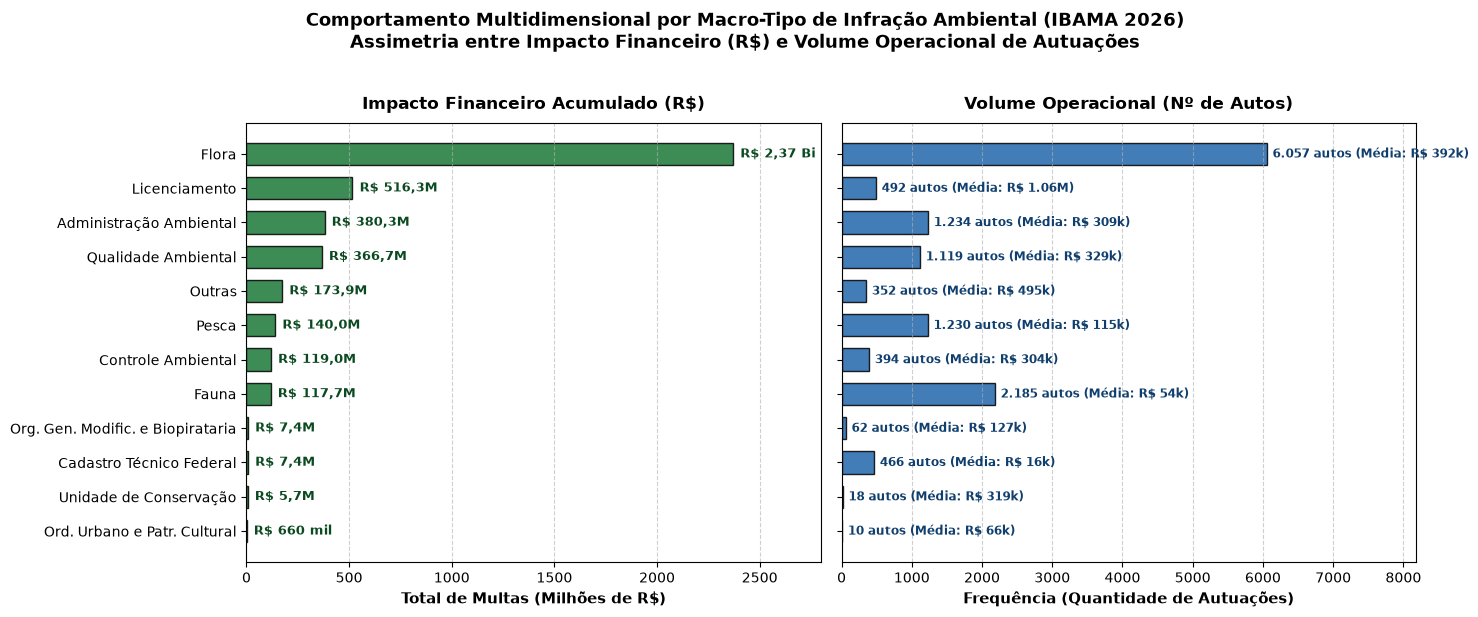

In [12]:
query9 = """
SELECT t.tipo_infracao, 
       COUNT(a.num_auto_infracao) AS total_autuacoes, 
       ROUND(SUM(a.valor_multa), 2) AS valor_total_multas, 
       ROUND(AVG(a.valor_multa), 2) AS valor_medio_multa
FROM Auto_Infracao a
JOIN Tipo_Infracao t ON a.id_tipo = t.id_tipo
GROUP BY t.tipo_infracao
ORDER BY valor_total_multas DESC;
"""

df_q9 = fetch(query9, conn)
display(df_q9)

# Visualização Comparativa Multidimensional: Impacto Financeiro vs. Frequência (Volume de Autos)
df_sorted = df_q9.iloc[::-1].reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

c_financeiro = '#1b7837'  # verde floresta (impacto financeiro)
c_frequencia = '#2166ac'  # azul cobalto (volume operacional)

# 1. Painel Esquerdo: Impacto Financeiro Acumulado
bars1 = ax1.barh(df_sorted['tipo_infracao'], df_sorted['valor_total_multas'] / 1e6, 
                 color=c_financeiro, edgecolor='black', alpha=0.85, height=0.65)
ax1.set_xlabel('Total de Multas (Milhões de R$)', fontsize=11, fontweight='bold')
ax1.set_title('Impacto Financeiro Acumulado (R$)', fontsize=12, fontweight='bold', pad=10)
ax1.grid(axis='x', linestyle='--', alpha=0.6)

for bar, val in zip(bars1, df_sorted['valor_total_multas'] / 1e6):
    if val >= 1000.0:
        txt = f'R$ {val/1000:,.2f} Bi'.replace(',', 'X').replace('.', ',').replace('X', '.')
    elif val >= 1.0:
        txt = f'R$ {val:,.1f}M'.replace(',', 'X').replace('.', ',').replace('X', '.')
    else:
        txt = f'R$ {val*1000:,.0f} mil'.replace(',', '.')
    ax1.text(val + 35, bar.get_y() + bar.get_height()/2, txt, 
             va='center', ha='left', fontsize=9, fontweight='bold', color='#0b4a20')
ax1.set_xlim(0, max(df_sorted['valor_total_multas'] / 1e6) * 1.18)

# 2. Painel Direito: Frequência / Volume Operacional com Valor Médio
bars2 = ax2.barh(df_sorted['tipo_infracao'], df_sorted['total_autuacoes'], 
                 color=c_frequencia, edgecolor='black', alpha=0.85, height=0.65)
ax2.set_xlabel('Frequência (Quantidade de Autuações)', fontsize=11, fontweight='bold')
ax2.set_title('Volume Operacional (Nº de Autos)', fontsize=12, fontweight='bold', pad=10)
ax2.grid(axis='x', linestyle='--', alpha=0.6)

for bar, qtd, avg in zip(bars2, df_sorted['total_autuacoes'], df_sorted['valor_medio_multa']):
    if avg >= 1e6:
        avg_str = f'R$ {avg/1e6:.2f}M'.replace('.', ',')
    elif avg >= 1e3:
        avg_str = f'R$ {avg/1e3:.0f}k'
    else:
        avg_str = f'R$ {avg:.0f}'
    txt = f'{qtd:,d} autos (Média: {avg_str})'.replace(',', '.')
    ax2.text(qtd + 80, bar.get_y() + bar.get_height()/2, txt, 
             va='center', ha='left', fontsize=8.5, fontweight='bold', color='#103f6e')
ax2.set_xlim(0, max(df_sorted['total_autuacoes']) * 1.35)

plt.suptitle('Comportamento Multidimensional por Macro-Tipo de Infração Ambiental (IBAMA 2026)\nAssimetria entre Impacto Financeiro (R$) e Volume Operacional de Autuações', 
             fontsize=13, fontweight='bold', y=1.02)

os.makedirs('graficos', exist_ok=True)
plt.savefig('graficos/consulta_9_macro_infracoes.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()


### 6.4.2 Consulta 10
**Descrição:** Agregação sobre a junção de `Auto_Infracao` e `Municipio` para totalizar a quantidade de infrações lavradas e o valor acumulado de multas em 2026 agrupados por Unidade Federativa (UF), destacando os 10 estados com maior passivo ambiental e comprovando a liderança do Pará com cerca de 38% do volume nacional (Investigação: Concentração geográfica por UF). Inclui visualização em gráfico de barras por estado e mapeamento geoespacial de dispersão de coordenadas (latitude vs. longitude).

,uf,total_autuacoes,valor_total_multas,pct_valor_nacional,valor_medio_multa
0,PA,2150,1.603235e+09,38.12,748475.62
1,MT,777,5.202327e+08,12.37,670402.93
2,RO,1005,4.427772e+08,10.53,442777.20
3,AM,705,3.382632e+08,8.04,481170.99
4,MS,189,1.637168e+08,3.89,866226.26
5,CE,458,1.299318e+08,3.09,283693.94
6,PR,673,1.259194e+08,2.99,189923.62
7,SC,684,1.006693e+08,2.39,148261.06
8,MA,374,9.433748e+07,2.24,252915.49
9,AC,590,6.973815e+07,1.66,118804.34


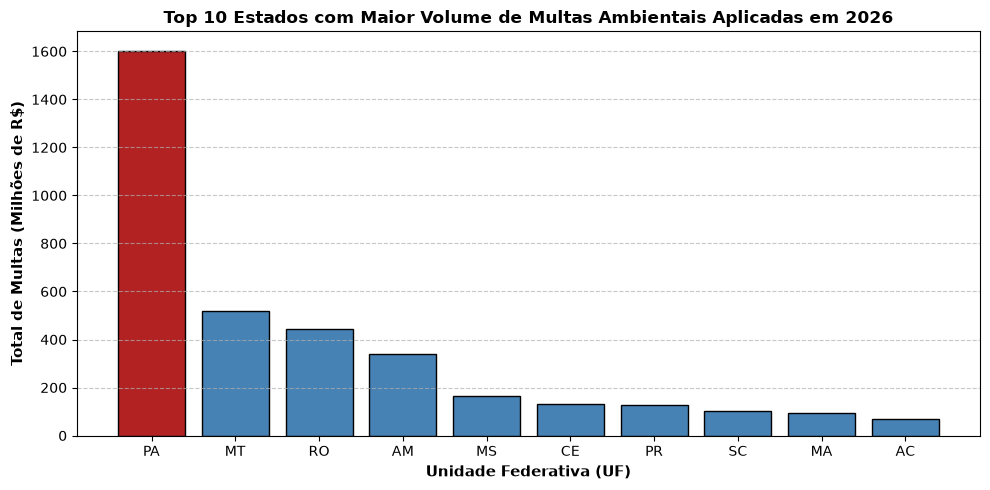

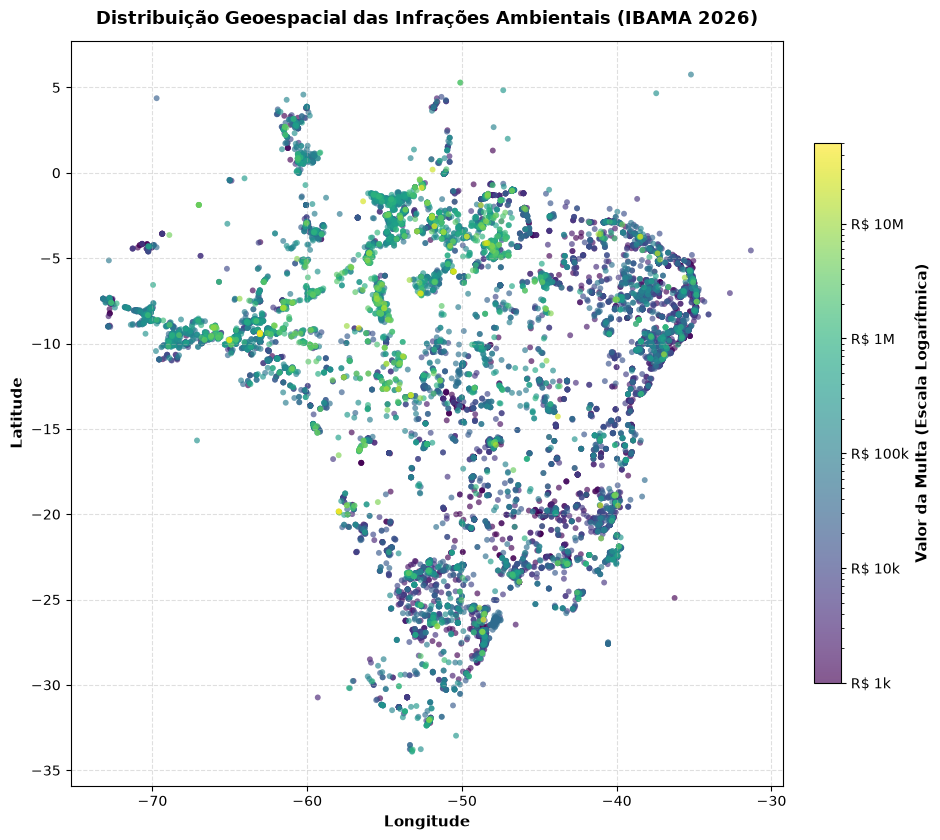

In [13]:
query10 = """
SELECT m.uf, 
       COUNT(a.num_auto_infracao) AS total_autuacoes, 
       ROUND(SUM(a.valor_multa), 2) AS valor_total_multas,
       ROUND(SUM(a.valor_multa) * 100.0 / (SELECT SUM(valor_multa) FROM Auto_Infracao), 2) AS pct_valor_nacional,
       ROUND(AVG(a.valor_multa), 2) AS valor_medio_multa
FROM Auto_Infracao a
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
GROUP BY m.uf
ORDER BY valor_total_multas DESC
LIMIT 10;
"""

df_q10 = fetch(query10, conn)
display(df_q10)

os.makedirs('graficos', exist_ok=True)

# 1. Gráfico de barras verticais por UF (Destaque do Pará ~38%)
plt.figure(figsize=(10, 5))
colors = ['firebrick' if uf == 'PA' else 'steelblue' for uf in df_q10['uf']]
plt.bar(df_q10['uf'], df_q10['valor_total_multas'] / 1e6, color=colors, edgecolor='black')
plt.ylabel('Total de Multas (Milhões de R$)', fontsize=11, fontweight='bold')
plt.xlabel('Unidade Federativa (UF)', fontsize=11, fontweight='bold')
plt.title('Top 10 Estados com Maior Volume de Multas Ambientais Aplicadas em 2026', fontsize=12, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('graficos/consulta_10_multas_por_uf.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Mapeamento Geoespacial Complementar: Dispersão de Coordenadas (Latitude vs. Longitude)
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter

query_geo = """
SELECT a.latitude, a.longitude, a.valor_multa, a.bioma, m.uf
FROM Auto_Infracao a
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
WHERE a.latitude IS NOT NULL AND a.longitude IS NOT NULL
  AND a.latitude BETWEEN -35 AND 6 AND a.longitude BETWEEN -75 AND -30
  AND a.valor_multa > 0
ORDER BY a.valor_multa ASC;
"""
df_geo = fetch(query_geo, conn)

fig, ax = plt.subplots(figsize=(9.5, 8.5))
sc = ax.scatter(
    df_geo['longitude'], 
    df_geo['latitude'], 
    c=df_geo['valor_multa'], 
    cmap='viridis', 
    norm=LogNorm(vmin=1000, vmax=50000000),
    alpha=0.65, 
    s=18, 
    edgecolors='none'
)

def format_reais(val, pos):
    if val >= 1e6:
        return f'R$ {val/1e6:.0f}M'
    elif val >= 1e3:
        return f'R$ {val/1e3:.0f}k'
    else:
        return f'R$ {val:.0f}'

cbar = plt.colorbar(sc, ax=ax, fraction=0.035, pad=0.04, format=FuncFormatter(format_reais))
cbar.set_label('Valor da Multa (Escala Logarítmica)', fontsize=11, fontweight='bold')

ax.set_xlabel('Longitude', fontsize=11, fontweight='bold')
ax.set_ylabel('Latitude', fontsize=11, fontweight='bold')
ax.set_title('Distribuição Geoespacial das Infrações Ambientais (IBAMA 2026)', fontsize=13, fontweight='bold', pad=12)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('graficos/analise_dispersao_geoespacial.png', dpi=300, bbox_inches='tight')
plt.show()


# 7. Autoavaliação dos membros

Abaixo são detalhadas as contribuições individuais desenvolvidas pelos membros da equipe ao longo de todas as etapas de planejamento, modelagem, implementação e análise analítica do Trabalho Prático 2:

* **Evandro Araújo Furlaneto Delgado (2025018830):**
  * 

* **Letícia Schmidt Tolentino Santos (2025014168):**
  * 

* **Victor Daniel Barbosa Thomé (2026303953):**
  * 

* **Vitória Medeiros Carrera de Oliveira (2019027245):**
  * 

* **Yuri Florentino Kosfeld (2022038503):**
  * 